In [2]:
# --- Orchestrator-Worker Workflow with Feedback ---
# Same as base orchestrator-worker, plus an evaluator loop that accepts or rejects
# the synthesized article. Rejected articles are revised up to 3 times.
from typing import Annotated, List, Literal, Optional, TypedDict,NotRequired
from pydantic import BaseModel, Field, field_validator, ValidationError
from operator import add
import operator
from langgraph.graph.message import add_messages
from langgraph.types import Send
from langgraph.graph import StateGraph, END, START
from langgraph.graph.state import CompiledStateGraph
from IPython.display import Image, display, Markdown
import re

# Google
from langchain_google_genai import ChatGoogleGenerativeAI

# HuggingFace
# from langchain_huggingface.embeddings import HuggingFaceEndpointEmbeddings
# from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint

# Cohere
from langchain_cohere import CohereEmbeddings

# Prompts
from langchain.prompts import PromptTemplate
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_core.messages import BaseMessage
from langchain_core.tools import tool

# Others
import os
from dotenv import load_dotenv
# # LangSmith
# import uuid
# from langchain_core.tracers.context import collect_runs
# from langchain_core.tracers.langchain import wait_for_all_tracers
# from langsmith import Client
# from langchain.callbacks.tracers import LangChainTracer

### **Orchestrator-Worker Agents: The Dynamic Version of Agents Parallelization**

In [3]:
from dotenv import load_dotenv

# Provide the filename as a string
load_dotenv('.env')

True

In [4]:
# loadding Google token
GOOGLE_API_KEY = os.getenv("GOOGLE_AI_STUDIO_GENERATIVE_MODEL_API_KEY")
# using Google from langchain
google_llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0.1,
    max_output_tokens=4096,
    api_key=GOOGLE_API_KEY
)

In [5]:
# loading Google token
GOOGLE_API_KEY = os.getenv("GOOGLE_AI_STUDIO_GENERATIVE_MODEL_API_KEY")
# using Google from langchain
google_llm_3_7 = ChatGoogleGenerativeAI(
    model="gemini-3.7-flash",
    temperature=0.1,
    max_output_tokens=4096,
    api_key=GOOGLE_API_KEY
)

In [6]:
class Section(BaseModel):
    title: str = Field(..., description="Title of the section, e.g., 'Early Life', 'Major Achievements'.")
    description: str = Field(..., description="Brief overview of what should be covered in this section.")

In [7]:
class OutlinePlan(BaseModel):
    sections: List[Section] = Field(..., description="Dynamically planned sections for the scientist report.")

In [8]:
class ScientistInput(BaseModel):
    scientist: str = Field(min_length=3, max_length=100, description="The name of the scientist")

    @field_validator("scientist")
    def validate_scientist(cls, value):
        value = value.strip()
        if not re.search("[a-zA-Z]", value):
            raise ValueError("Scientist name must contain letters.")
        return value

In [9]:
class RefinedArticleOutput(BaseModel):
    refined_article: str = Field(description="Refined and synthesized final article under 1000 words.")

In [10]:
# Evaluator/Feedback/Critic
class EvaluatorCritic(BaseModel):
    status: Literal["ACCEPTED", "REJECTED"] = Field(
        description="Decide if the Refined Article is acceptable or not"

    )

    feedback: str = Field(
        description="Give a constructive reason why the article is not good enougn with points for improvement"
    )

In [11]:
# Structured LLMs 
planner_llm = google_llm.with_structured_output(OutlinePlan)
refined_article_llm = google_llm.with_structured_output(RefinedArticleOutput)

# Evaluator/Feedback/Critic
evaluator_llm = google_llm_3_7.with_structured_output(EvaluatorCritic)

In [12]:
# Shared Main Graph State: Orchestrator State
class State(TypedDict):
    input: str
    scientist: NotRequired[str]
    sections: NotRequired[List[Section]]
    # Key reducer operator.add allows parallel workers to append outputs safetly
    completed_sections: Annotated[List[str], add] # expects a list of strings
    article: NotRequired[str]
    refined_article: NotRequired[str]

    # EvaluatorCritic
    feedback: NotRequired[str]
    accepted_rejected: NotRequired[str]
    feedback_count: NotRequired[int] # Crucial: Persist loop count in state

In [13]:
# Individual Worker State
class WorkerState(TypedDict):
    scientist: str
    section: Section

In [14]:
# Extracts the scientist's name from the user input via LLM
def scientist_name_extraction(state:State):
    # Extract the scientist's name from the input
    prompt = PromptTemplate.from_template(
    """Extract the scientist's name from the input provided by the user. 
    The input is: {input}.
    """
    )

    extraction_data  = {"input": state["input"]}
    extraction_chain  = prompt | google_llm
    response = extraction_chain.invoke(extraction_data)

    try:
        validated = ScientistInput.model_validate(
                    {
                    "scientist": response.content.strip()
                    }
        )
        # Assuming the response contains the extracted name in a field called 'content'
        return {"scientist": validated.scientist}

    except ValidationError as e:
        print(e.errors()[0]["msg"])

In [15]:
# Dynamically plans article sections using structured LLM output
def orchestrator(state: State):
    """
    Orchestrator: Dynamically breaks down the topic into 3-5 key sections
    tailored to the specific scientist (e.g. Early Life, Theories, Impact).
    """
    plan = planner_llm.invoke([
        SystemMessage(content="""You are an expert editor. Create an outline plan of 2 distinct sections for an article about the given scientist.
        Which covers the history and the achievements of the scientist
        """),
        HumanMessage(content=f"Scientist: {state['scientist']}")
    ])

    # Initialise state fields
    return {
        "sections": plan.sections,
        "completed_sections": []
    }

In [16]:
def worker_section_writer(state: WorkerState):
    """
    Worker: Executes a single section task generated by the orchestrator.
    Executes in parallel per section via Send API.
    """
    prompt = PromptTemplate.from_template(
        """Write a comprehensive section for an article about {scientist}.
        Section Title: {title}
        Section Focus: {description}
        
        Write only the section content in clear markdown. Do not include extra introductions or intros.
        """
    )
    
    chain = prompt | google_llm
    response = chain.invoke({
        "scientist": state["scientist"],
        "title": state["section"].title,
        "description": state["section"].description
    })
    
    formatted_section = f"### {state['section'].title}\n\n{response.content}"
    
    # Reducer appends this entry into state["completed_sections"]
    return {"completed_sections": [formatted_section]}

In [17]:
# Merges all worker-written sections into a single article, optionally refining if >1000 words
def synthesizer(state: State):
    """
    Synthesizer: Takes all completed section outputs from parallel workers,
    combines them, and applies word-length checks before optionally refining.
    """
    completed_sections = state.get("completed_sections", [])
    current_count = state.get("feedback_count", 0)
    
    # 1. Guard check: Ensure worker outputs exist
    if not completed_sections:
        return {
            "article": "",
            "refined_article": "Error: Article was not generated properly."
        }

    # 2. Combine section outputs into full draft
    generated_article = "\n\n".join(completed_sections)
    article_length = len(generated_article.split())

    # 3. Branching logic based on word count
    if article_length > 1000:
        prompt = PromptTemplate.from_template(
            """Summarise the following article about {scientist} in less than 1000 words from given article\n{article}.\n
            It should be concise and clear, and should not lose the main points of the article. 
            Final Article must be in Markdown format with different sections. For example;
            ## **Title**

            ### **History**

            ### **Achievements**

            ### **Main Contributions**
            
            ## **Conclusion**

            This is just an example you can modify
            
            You must give the article in Markdown format
            """
        )
        refined_article_data = {
            "scientist": state["scientist"], 
            "article": generated_article
        }
        refined_article_chain = prompt | refined_article_llm
        response = refined_article_chain.invoke(refined_article_data)

        # Null check to prevent 'NoneType' object has no attribute 'refined_article'
        if response and hasattr(response, "refined_article") and response.refined_article:
            refined_text = response.refined_article
        else:
            print("Warning: Structured output returned None. Falling back to generated draft.")
            refined_text = generated_article

        return {
            "article": generated_article,
            "refined_article": refined_text,
            "feedback_count": current_count        
        }
    else:
        print("Initial article is already under 1000 words. No refinement needed.")
        return {
            "article": generated_article,
            "refined_article": generated_article,
            "feedback_count": current_count        
        }

In [18]:
# Uses Send API to spawn parallel worker nodes, one per planned section
def assign_workers(state: State):
    """
    Conditional edge function that uses Send API to dynamically 
    spawn 'worker_section_writer' nodes for every planned section.
    """
    return [
        Send(
            "worker_section_writer", 
            {
                "scientist": state["scientist"], 
                "section": section
            }
        ) 
        for section in state["sections"]
    ]

In [19]:
# Revises the article using evaluator feedback; increments feedback_count
def refine_article_with_feedback(state: State):
    generated_article = state.get("article", "")
    current_count = state.get("feedback_count", 0)

    feedback_prompt = PromptTemplate.from_template(
        """Improve the refined article\n{refined_article}.\nWith the provided feedback \n{feedback}
        You must give the article in Markdown format.
        """
    )
    feedback_data = {
        "refined_article": state.get("refined_article", generated_article),
        "feedback": state["feedback"]
    }
    
    feedback_chain = feedback_prompt | refined_article_llm
    response = feedback_chain.invoke(feedback_data)
    
    refined_text = response.refined_article if (response and response.refined_article) else generated_article
    current_count+=1
    print(f"Article was rejected {current_count} time(s)!")
    return {
        "refined_article": refined_text,
        "feedback_count": current_count 
    }

In [20]:
# LLM critic evaluates the refined article and returns ACCEPTED/REJECTED with feedback
def llm_evaluator(state: State):
    """Evaluation of Articles"""
    refined_text = state.get("refined_article", state.get("article", ""))
    critic = evaluator_llm.invoke([
    SystemMessage(content="""You are an expect critic of articles with 5+ years' of expereience. Kindly crtitc the given article.
    """),
    HumanMessage(content=f"refined_article: {refined_text}")
    ])

    print(f"Article was {critic.status}")
    return {
        "accepted_rejected": critic.status,
        "feedback":critic.feedback
    }

In [21]:
# Returns ACCEPTED if max retries (3) reached, otherwise passes through evaluator verdict
def route_feedback(state:State):
    """Route the refined article or end based upon the feedback from the evaluator"""
    if state.get("feedback_count", 0) >= 3:
        return "ACCEPTED"
    return state.get("accepted_rejected", "ACCEPTED")

In [22]:
# Assembles the full graph: extraction -> orchestrator -> Send() -> workers -> synthesizer -> feedback loop
def build_orchestrator_worker_graph():
    workflow = StateGraph(State)

    # Add Nodes
    workflow.add_node("scientist_name_extraction", scientist_name_extraction)
    workflow.add_node("orchestrator",orchestrator)
    workflow.add_node("worker_section_writer", worker_section_writer)
    workflow.add_node("synthesizer", synthesizer)
    workflow.add_node("refine_article_with_feedback", refine_article_with_feedback)  # NEW NODE
    workflow.add_node("evaluate_feedback_llm",llm_evaluator)

    # Static Edges
    workflow.add_edge(START, "scientist_name_extraction")
    workflow.add_edge("scientist_name_extraction","orchestrator")

    # Orchestrator --> Dynamic Parallel Workers via Send()
    workflow.add_conditional_edges(
        "orchestrator",
        assign_workers,
        ["worker_section_writer"]
    )

    # Workers --> Synthesizer --> END
    workflow.add_edge("worker_section_writer","synthesizer")
    
    # Feeback Route
    workflow.add_edge("synthesizer", "evaluate_feedback_llm")

    # adding the evaluation path
    workflow.add_edge("refine_article_with_feedback", "evaluate_feedback_llm")
    workflow.add_conditional_edges(
        "evaluate_feedback_llm",
        route_feedback,
        {
            "ACCEPTED": END,
            "REJECTED": "refine_article_with_feedback" # Routes directly to feedback node
        }
    )


    return workflow.compile()

In [23]:
graph = build_orchestrator_worker_graph()

In [24]:
# Renders the LangGraph workflow as a Mermaid diagram
def graph_visualiser(graph):
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception as e:
        print(e)

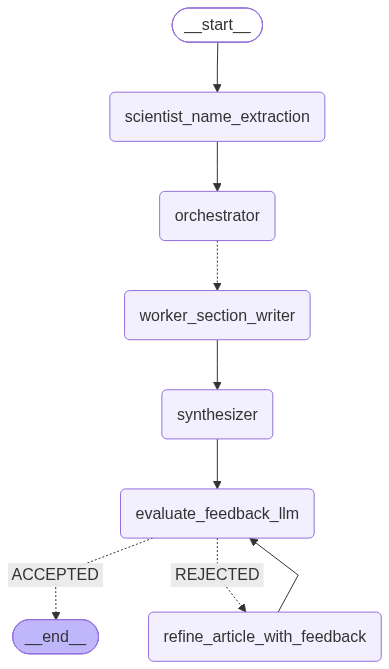

In [25]:
graph_visualiser(graph)

In [26]:
results = graph.invoke({
    "input": "Write an in-depth article about Stephen William Hawking"
    # "input": "Write an in-depth article about Marie Curie"
})

Article was ACCEPTED


In [33]:
# Formats and displays all state fields using IPython Markdown rendering
def results_formatting(results:dict):
    """The Results formatter"""
    for key,value in results.items():
        if isinstance(value, str):
            print(f"{key.upper()}")
            display(Markdown(value.strip()))
        elif isinstance(value, list):
            print(f"{key.upper()}\nFirst Value in the list is\n{value[0]}\n")
        else:
            print(f"{key.upper()}\n{value}\n")

In [34]:
results

{'input': 'Write an in-depth article about Stephen William Hawking',
 'scientist': 'Stephen William Hawking',
 'sections': [Section(title='Early Life and Academic Journey', description="This section will detail Stephen Hawking's early life, education, and the onset and progression of his motor neuron disease, highlighting how these factors shaped his scientific pursuits."),
  Section(title='Groundbreaking Contributions to Physics', description="This section will focus on Stephen Hawking's major scientific achievements, including his work on black holes, singularity theorems, Hawking radiation, and his efforts to popularize science.")],
 'completed_sections': ['### Early Life and Academic Journey\n\nStephen William Hawking was born on January 8, 1942, in Oxford, England, precisely 300 years after the death of Galileo Galilei. His parents, Frank and Isobel Hawking, were both Oxford graduates with intellectual pursuits; his father was a medical researcher specializing in tropical diseases

In [36]:
sections_total = 0
for section_num in range(len(results['sections'])):
    sections_total += 1

print(f"Total Sections/Workers present are: {sections_total}")

Total Sections/Workers present are: 2


In [35]:
results_formatting(results)

INPUT


Write an in-depth article about Stephen William Hawking

SCIENTIST


Stephen William Hawking

SECTIONS
First Value in the list is
title='Early Life and Academic Journey' description="This section will detail Stephen Hawking's early life, education, and the onset and progression of his motor neuron disease, highlighting how these factors shaped his scientific pursuits."

COMPLETED_SECTIONS
First Value in the list is
### Early Life and Academic Journey

Stephen William Hawking was born on January 8, 1942, in Oxford, England, precisely 300 years after the death of Galileo Galilei. His parents, Frank and Isobel Hawking, were both Oxford graduates with intellectual pursuits; his father was a medical researcher specializing in tropical diseases, and his mother was a political activist. The family, including younger sisters Mary and Philippa and adopted brother Edward, moved to St Albans, Hertfordshire, where Stephen attended St Albans School. Though not initially a stellar student, he displayed an early fascination with how things worked, often dismantling radios and clocks, and poss

...

FEEDBACK


The article is well-structured, clear, and accurately captures the major milestones in Stephen Hawking's life and scientific career (notably the singularity theorems, area theorem, Hawking radiation, and 'A Brief History of Time').

Points for further improvement:
1. Biographical Completeness: The article introduces his 1963 diagnosis and life span prognosis but omits his death date (March 14, 2018), which leaves the biographical narrative incomplete.
2. Academic Roles & Recognition: Mentioning his prestigious tenure as the Lucasian Professor of Mathematics at Cambridge (a chair once held by Isaac Newton) would provide valuable context regarding his academic standing.
3. Assistive Technology: Touching upon his iconic computer-generated voice system and wheelchair technology would enrich the portrayal of his perseverance and cultural impact.

ACCEPTED_REJECTED


ACCEPTED

FEEDBACK_COUNT
0

